# Decoding Citi Bike Demand: The Impact of Weather, Seasonality and Holidays in NYC

**Advanced Data Science (CSE3105) - Final project notebook - Group 14**  
Harshit Kumar (240470) - Ishaan Jatain (240484) - Himanshu Yadav (240478) - Hrash (240468)  
Repository: https://github.com/harshitkumar24cse/citibike-demand

**Question:** how much do weather, season and holidays change hourly Citi Bike demand, and do members and casual riders respond differently? **Stakeholder:** Citi Bike's operations and rebalancing team.

This notebook runs the whole analysis in order, following BADIR:

1. Build the dataset (SSOT)
2. Data quality, hourly aggregation and EDA
3. Hypothesis testing
4. Machine-learning check (gradient boosting + SHAP)
5. Decisions: demand scenarios and station priority

The code in each cell is the same as in the project's `.py` scripts, so every number matches the report and slides.

## Part 1 - Build the single source of truth (SSOT) dataset

`build_ssot.py` reads 15.3 million Citi Bike trips (April, June, October, December 2025), keeps a seeded 25% sample, removes duplicates and impossible trips, converts the weather from UTC to New York time and joins weather, station capacity and holidays into one table: **3,822,094 trips x 41 variables**, saved as `ssot.parquet`.

Rebuilding needs the 3 GB of trip files in `trips/` and takes 5-10 minutes, so it is switched off by default; the notebook uses the saved `ssot.parquet`. Set `REBUILD = True` to run it again.

In [1]:
import os
import subprocess
import sys

REBUILD = False  # True = rebuild ssot.parquet from the raw trip files in trips/

if REBUILD:
    subprocess.run([sys.executable, "build_ssot.py"], check=True)

print("ssot.parquet found:", os.path.exists("ssot.parquet"))
print(open("sources_summary.txt", encoding="utf-8").read())  # the build log: counts, removals, weather check

ssot.parquet found: True
== 1. Trips ==
  202504-citibike-tripdata_1.csv: 1,000,000 raw rows
  202504-citibike-tripdata_2.csv: 1,000,000 raw rows
  202504-citibike-tripdata_3.csv: 1,000,000 raw rows
  202504-citibike-tripdata_4.csv: 724,596 raw rows
  202506-citibike-tripdata_1.csv: 1,000,000 raw rows
  202506-citibike-tripdata_2.csv: 1,000,000 raw rows
  202506-citibike-tripdata_3.csv: 1,000,000 raw rows
  202506-citibike-tripdata_4.csv: 1,000,000 raw rows
  202506-citibike-tripdata_5.csv: 759,345 raw rows
  202510-citibike-tripdata_1.csv: 1,000,000 raw rows
  202510-citibike-tripdata_2.csv: 1,000,000 raw rows
  202510-citibike-tripdata_3.csv: 1,000,000 raw rows
  202510-citibike-tripdata_4.csv: 1,000,000 raw rows
  202510-citibike-tripdata_5.csv: 731,900 raw rows
  202512-citibike-tripdata_1.csv: 1,000,000 raw rows
  202512-citibike-tripdata_2.csv: 1,000,000 raw rows
  202512-citibike-tripdata_3.csv: 91,620 raw rows
  Raw rows across files: 15,307,461; kept after 25% sampling: 3,826,

## Part 2 - Check data quality, aggregate to hourly demand and explore the data (EDA)

From `stage2_eda.py`.

### Step 2.1 - Import libraries and set up output folders and chart style

Libraries, output folders and the chart colours used in every figure.

In [2]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from summarytools import dfSummary

OUT = "outputs"
FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)

SEASONS = {4: "spring", 6: "summer", 10: "autumn", 12: "winter"}
SEASON_ORDER = ["spring", "summer", "autumn", "winter"]

# chart style: two-series charts use categorical slots 1 and 2 of the reference palette
C1, C2 = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 150,
})

report = []  # lines for data_quality.txt


def log(msg=""):
    print(msg)
    report.append(msg)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, name), bbox_inches="tight", facecolor="white")
    plt.close(fig)

### Step 2.2 - Load the trip dataset, hourly weather and holidays

Load the final trip dataset (SSOT), the hourly weather table and the 2025 holiday list.

In [3]:
trips = pd.read_parquet("ssot.parquet")
weather = pd.read_csv("datasets/2_weather_hourly_newyork.csv", parse_dates=["hour_ts"])
holidays = pd.read_csv("datasets/5_holidays_2025.csv", parse_dates=["date"])

### Step 2.3 - Check data quality and create the dfSummary report

Check the trip data before analysing it: size, duplicates, rider and bike mix, trip durations and missing values. `dfSummary` (from `summarytools`) writes a one-page report of every column to `outputs/dfsummary_ssot.html`. This cell takes a minute or two on 3.8 million rows.

In [4]:
log("== Data-quality summary (trip level) ==")
log(f"Rows: {len(trips):,}   columns: {trips.shape[1]}")
log(f"Duplicate ride_id: {trips['ride_id'].duplicated().sum():,}")
log(f"Trips per month: {trips.groupby('month').size().to_dict()}")
log(f"Member / casual: {trips['member_casual'].value_counts().to_dict()}")
log(f"Bike type: {trips['rideable_type'].value_counts().to_dict()}")
d = trips["duration_min"]
log(f"Duration (min): median {d.median():.1f}, mean {d.mean():.1f}, "
    f"p95 {d.quantile(.95):.1f}, max {d.max():.1f}")
log(f"Distance (km): median {trips['distance_km'].median():.2f}, "
    f"missing {trips['distance_km'].isna().mean():.2%}")
log(f"Round trips (same start and end station): {trips['same_station'].mean():.2%}")
miss = trips.isna().mean().sort_values(ascending=False)
log("Columns with missing values:")
for c, v in miss[miss > 0].items():
    log(f"  {c}: {v:.2%}")

# dfSummary: one table with type, missing values, distinct values and a mini chart per column
with open(os.path.join(OUT, "dfsummary_ssot.html"), "w", encoding="utf-8") as fh:
    fh.write(dfSummary(trips).to_html())
log("Saved dfSummary of the trip dataset: outputs/dfsummary_ssot.html")

== Data-quality summary (trip level) ==
Rows: 3,822,094   columns: 41


Duplicate ride_id: 0
Trips per month: {4: 930120, 6: 1187748, 10: 1181673, 12: 522553}
Member / casual: {'member': 3177895, 'casual': 644199}
Bike type: {'electric_bike': 2703455, 'classic_bike': 1118639}


Duration (min): median 8.7, mean 11.9, p95 31.6, max 179.9
Distance (km): median 1.49, missing 0.29%
Round trips (same start and end station): 1.93%


Columns with missing values:
  end_station_capacity: 4.53%
  start_station_capacity: 3.36%
  distance_km: 0.29%
  avg_speed_kmh: 0.29%
  end_lat: 0.25%
  end_lng: 0.25%
  end_station_id: 0.25%
  end_station_name: 0.22%
  start_lat: 0.05%
  start_station_id: 0.05%
  start_station_name: 0.05%
  start_lng: 0.05%


Saved dfSummary of the trip dataset: outputs/dfsummary_ssot.html


### Step 2.4 - Aggregate trips into trips per hour (2,928 hours)

Demand means trips per hour, and weather is measured per hour, so we count trips by the hour they started. The result is 2,928 hourly rows, each with member and casual trips and that hour's weather and calendar fields.

In [5]:
counts = (trips.groupby(["start_hour_ts", "member_casual"], observed=True).size()
          .unstack(fill_value=0).rename(columns={"member": "member_trips", "casual": "casual_trips"}))
hourly = weather.set_index("hour_ts").join(counts, how="left")
hourly[["member_trips", "casual_trips"]] = hourly[["member_trips", "casual_trips"]].fillna(0).astype(int)
hourly["total_trips"] = hourly["member_trips"] + hourly["casual_trips"]
hourly["casual_share"] = hourly["casual_trips"] / hourly["total_trips"].replace(0, np.nan)

ts = hourly.index
hourly["date"] = ts.normalize()
hourly["month"] = ts.month
hourly["season"] = hourly["month"].map(SEASONS)
hourly["hour"] = ts.hour
hourly["day_of_week"] = ts.dayofweek  # Mon=0
hourly["is_weekend"] = (hourly["day_of_week"] >= 5).astype(int)
hourly["is_holiday"] = hourly["date"].isin(holidays["date"]).astype(int)
hourly["is_non_working_day"] = ((hourly["is_weekend"] == 1) | (hourly["is_holiday"] == 1)).astype(int)
hourly["is_rush_hour"] = ((hourly["is_non_working_day"] == 0) &
                          hourly["hour"].isin([7, 8, 9, 16, 17, 18, 19])).astype(int)
hourly = hourly.reset_index().rename(columns={"index": "hour_ts"})
hourly.to_csv(os.path.join(OUT, "hourly_demand.csv"), index=False)
with open(os.path.join(OUT, "dfsummary_hourly.html"), "w", encoding="utf-8") as fh:
    fh.write(dfSummary(hourly).to_html())

log("\n== Hourly demand table ==")
log(f"Hours: {len(hourly):,}  (trips summed: {hourly['total_trips'].sum():,})")
log(f"Hours with zero trips: {(hourly['total_trips'] == 0).sum()}")
t = hourly["total_trips"]
log(f"Trips per hour: mean {t.mean():.0f}, median {t.median():.0f}, min {t.min()}, max {t.max()}")
log(f"Rainy hours (>= 0.1 mm): {hourly['is_raining'].sum()} of {len(hourly)} "
    f"({hourly['is_raining'].mean():.1%})")
log("Mean trips per hour by season: " +
    str(hourly.groupby("season")["total_trips"].mean().reindex(SEASON_ORDER).round(0).to_dict()))
log("Mean temperature by season (C): " +
    str(hourly.groupby("season")["temp_c"].mean().reindex(SEASON_ORDER).round(1).to_dict()))


== Hourly demand table ==
Hours: 2,928  (trips summed: 3,822,094)
Hours with zero trips: 0
Trips per hour: mean 1305, median 1110, min 4, max 5021
Rainy hours (>= 0.1 mm): 421 of 2928 (14.4%)
Mean trips per hour by season: {'spring': 1292.0, 'summer': 1650.0, 'autumn': 1588.0, 'winter': 702.0}
Mean temperature by season (C): {'spring': 12.0, 'summer': 23.3, 'autumn': 14.0, 'winter': -0.3}


### Step 2.5 - Exploratory data analysis: draw the EDA charts

Exploratory charts: daily profile, temperature, rain, seasons, trip duration, casual share, weather correlations and the three holidays. The charts are saved to `outputs/figures` and shown below.

In [6]:
# 4.1 Daily profile: weekday vs weekend (H5)
prof = hourly.groupby(["is_non_working_day", "hour"])["total_trips"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(prof.index, prof[0], color=C1, lw=2, marker="o", ms=4, label="Working day")
ax.plot(prof.index, prof[1], color=C2, lw=2, marker="o", ms=4, label="Weekend / holiday")
ax.set(title="Average trips per hour across the day", xlabel="Hour of day",
       ylabel="Trips per hour (25% sample)", xticks=range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
save(fig, "01_daily_profile_weekday_weekend.png")

# 4.2 Trips vs temperature, members and casual riders (H1, H3) - small multiples, own scales
hourly["temp_bin"] = (hourly["temp_c"] // 2) * 2 + 1  # 2 C bins, labelled by mid-point
tb = hourly.groupby("temp_bin").agg(member=("member_trips", "mean"), casual=("casual_trips", "mean"),
                                   n=("total_trips", "size"))
tb = tb[tb["n"] >= 10]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, col, color, name in [(axes[0], "member", C1, "Members"), (axes[1], "casual", C2, "Casual riders")]:
    ax.scatter(hourly["temp_c"], hourly[f"{col}_trips"], s=4, color=color, alpha=0.15, lw=0)
    ax.plot(tb.index, tb[col], color=color, lw=2, marker="o", ms=4)
    ax.set(title=name, xlabel="Temperature (C)", ylabel="Trips per hour")
    ax.set_ylim(bottom=0)
fig.suptitle("Trips per hour vs temperature (dots = hours, line = average per 2 C)",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
save(fig, "02_trips_vs_temperature_member_casual.png")

# 4.3 Rain vs dry by season (H2)
rd = hourly.groupby(["season", "is_raining"])["total_trips"].mean().unstack().reindex(SEASON_ORDER)
x = np.arange(len(rd))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, rd[0], width=0.38, color=C1, label="Dry hour")
ax.bar(x + 0.2, rd[1], width=0.38, color=C2, label="Rainy hour (>= 0.1 mm)")
for i, (dry, wet) in enumerate(zip(rd[0], rd[1])):
    ax.text(i + 0.2, wet, f"{(wet / dry - 1):+.0%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set(title="Average trips per hour: dry vs rainy hours, by season", ylabel="Trips per hour",
       xticks=x, xticklabels=[s.title() for s in rd.index])
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
save(fig, "03_rain_vs_dry_by_season.png")

# 4.4 Distribution of hourly demand by season (seasons, Kruskal-Wallis later)
fig, ax = plt.subplots(figsize=(8, 4.2))
data = [hourly.loc[hourly["season"] == s, "total_trips"] for s in SEASON_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=INK, lw=1.5))
for b in bp["boxes"]:
    b.set(facecolor="#9ec5f4", edgecolor=C1)
ax.set(title="Trips per hour by season", ylabel="Trips per hour",
       xticks=range(1, 5), xticklabels=[f"{s.title()}\n({m})" for s, m in
                                         zip(SEASON_ORDER, ["Apr", "Jun", "Oct", "Dec"])])
ax.grid(axis="x", visible=False)
save(fig, "04_hourly_demand_by_season.png")

# 4.5 Trip duration, members vs casual riders (H4) - trip level
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(0, 61, 1)
for rider, color, name in [("member", C1, "Members"), ("casual", C2, "Casual riders")]:
    dd = trips.loc[trips["member_casual"] == rider, "duration_min"]
    over = (dd > 60).mean()
    ax.hist(dd[dd <= 60], bins=bins, density=True, histtype="step", lw=2, color=color,
            label=f"{name}: median {dd.median():.1f} min ({over:.1%} over 60 min not shown)")
ax.set(title="Trip duration: members vs casual riders", xlabel="Trip duration (minutes)",
       ylabel="Share of trips")
ax.legend(loc="upper right")
save(fig, "05_trip_duration_member_casual.png")

# 4.6 Casual share across the day, working vs non-working days (H5)
cs = (hourly.groupby(["is_non_working_day", "hour"])[["casual_trips", "total_trips"]].sum())
cs = (cs["casual_trips"] / cs["total_trips"]).unstack(0)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(cs.index, cs[0] * 100, color=C1, lw=2, marker="o", ms=4, label="Working day")
ax.plot(cs.index, cs[1] * 100, color=C2, lw=2, marker="o", ms=4, label="Weekend / holiday")
ax.set(title="Share of trips by casual riders across the day", xlabel="Hour of day",
       ylabel="Casual share (%)", xticks=range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(loc="lower right")
save(fig, "06_casual_share_by_hour.png")

# 4.7 Correlation of hourly trips with weather variables
wvars = {"temp_c": "Temperature", "humidity_pct": "Humidity", "precip_mm": "Precipitation",
         "wind_speed_ms": "Wind speed", "cloud_cover_pct": "Cloud cover",
         "sea_level_pressure_hpa": "Pressure"}
corr = hourly[list(wvars) + ["total_trips"]].corr(method="spearman")["total_trips"].drop("total_trips")
corr = corr.rename(wvars).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(corr.index, corr.values, color=[C2 if v < 0 else C1 for v in corr.values], height=0.6)
for i, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set(title="Correlation of trips per hour with weather (Spearman)", xlim=(-1, 1),
       xlabel="Correlation (-1 to +1)")
ax.grid(axis="y", visible=False)
save(fig, "07_weather_correlations.png")

# 4.8 Holidays: only 3 in our months, so we describe them instead of testing them.
# Each holiday is compared with the normal days of the same weekday in the same month.
daily = hourly.groupby("date").agg(trips=("total_trips", "sum"), casual=("casual_trips", "sum"),
                                   temp=("temp_c", "mean"), rain_hours=("is_raining", "sum"),
                                   holiday=("is_holiday", "max"))
daily["weekday"] = daily.index.dayofweek
daily["month"] = daily.index.month
rows = []
for day, h in daily[daily["holiday"] == 1].iterrows():
    normal = daily[(daily["holiday"] == 0) & (daily["weekday"] == h["weekday"]) & (daily["month"] == h["month"])]
    name = holidays.loc[holidays["date"] == day, "holiday_name"].iloc[0]
    rows.append({"date": day.date(), "holiday": name, "weekday": day.day_name(),
                 "holiday_trips": int(h["trips"]), "normal_day_trips": round(normal["trips"].mean()),
                 "change_pct": round((h["trips"] / normal["trips"].mean() - 1) * 100, 1),
                 "holiday_casual_share_pct": round(h["casual"] / h["trips"] * 100, 1),
                 "normal_casual_share_pct": round(normal["casual"].sum() / normal["trips"].sum() * 100, 1),
                 "holiday_temp_c": round(h["temp"], 1), "holiday_rain_hours": int(h["rain_hours"])})
hol = pd.DataFrame(rows)
hol.to_csv(os.path.join(OUT, "holidays_described.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(hol))
ax.bar(x - 0.2, hol["normal_day_trips"], width=0.38, color=C1, label="Normal day (same weekday, same month)")
ax.bar(x + 0.2, hol["holiday_trips"], width=0.38, color=C2, label="Holiday")
for i, c in enumerate(hol["change_pct"]):
    ax.text(i + 0.2, hol["holiday_trips"][i], f"{c:+.0f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set(title="Trips on the 3 holidays vs a normal day", ylabel="Trips per day (25% sample)", xticks=x,
       xticklabels=[f"{n}\n{d}" for n, d in zip(["Juneteenth", "Columbus Day", "Christmas"], hol["weekday"])])
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
save(fig, "09_holidays_vs_normal_day.png")

log("\nHolidays (described, not tested):")
for _, r in hol.iterrows():
    log(f"  {r['holiday']} ({r['weekday']}): {r['holiday_trips']:,} trips vs {r['normal_day_trips']:,} "
        f"on a normal {r['weekday']} ({r['change_pct']:+.1f}%); casual share {r['holiday_casual_share_pct']}% "
        f"vs {r['normal_casual_share_pct']}%; {r['holiday_temp_c']} C, {r['holiday_rain_hours']} rainy hours")

log("\nSpearman correlation of trips per hour with weather:")
for k, v in corr.sort_values(ascending=False).items():
    log(f"  {k}: {v:+.2f}")

with open(os.path.join(OUT, "data_quality.txt"), "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))
print(f"\nSaved outputs/hourly_demand.csv, outputs/data_quality.txt and {len(os.listdir(FIG))} charts.")


Holidays (described, not tested):
  Juneteenth National Independence Day (Thursday): 35,467 trips vs 46,372 on a normal Thursday (-23.5%); casual share 20.7% vs 18.1%; 25.6 C, 7 rainy hours
  Columbus Day (Monday): 15,291 trips vs 36,360 on a normal Monday (-57.9%); casual share 11.0% vs 13.9%; 13.5 C, 18 rainy hours
  Christmas Day (Thursday): 6,304 trips vs 24,879 on a normal Thursday (-74.7%); casual share 20.0% vs 9.6%; 1.9 C, 0 rainy hours

Spearman correlation of trips per hour with weather:
  Temperature: +0.49
  Wind speed: +0.06
  Pressure: +0.02
  Cloud cover: -0.08
  Precipitation: -0.15
  Humidity: -0.45

Saved outputs/hourly_demand.csv, outputs/data_quality.txt and 13 charts.


**Charts produced in this part** (saved in `outputs/figures`):

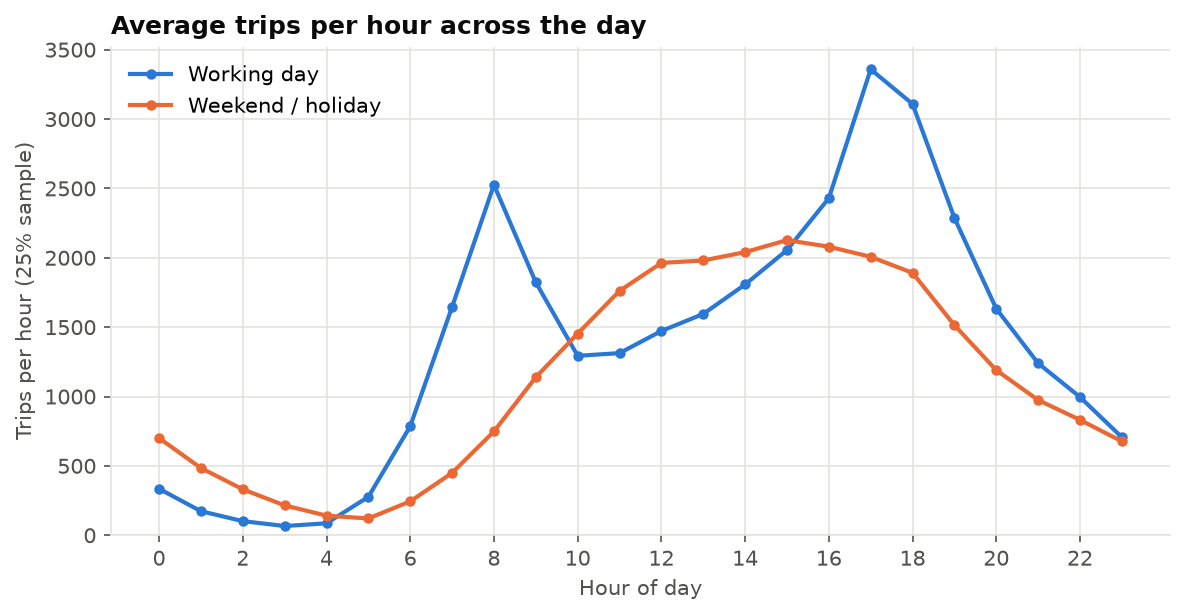

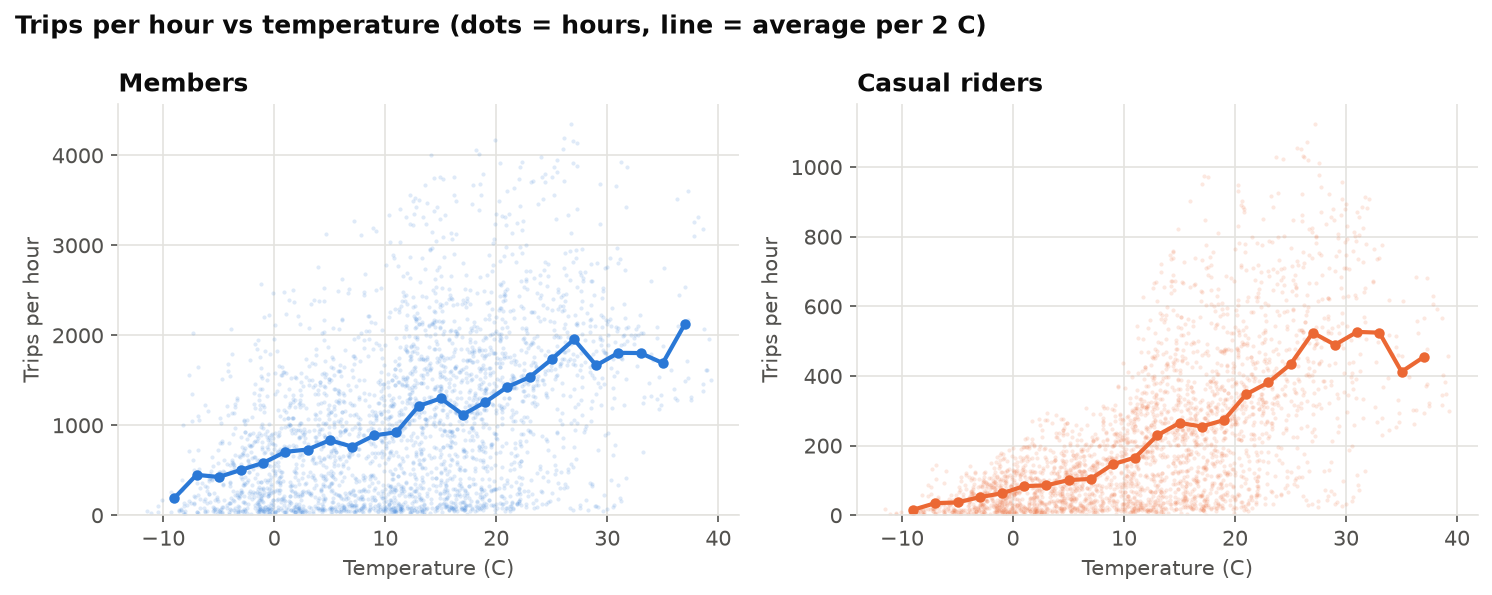

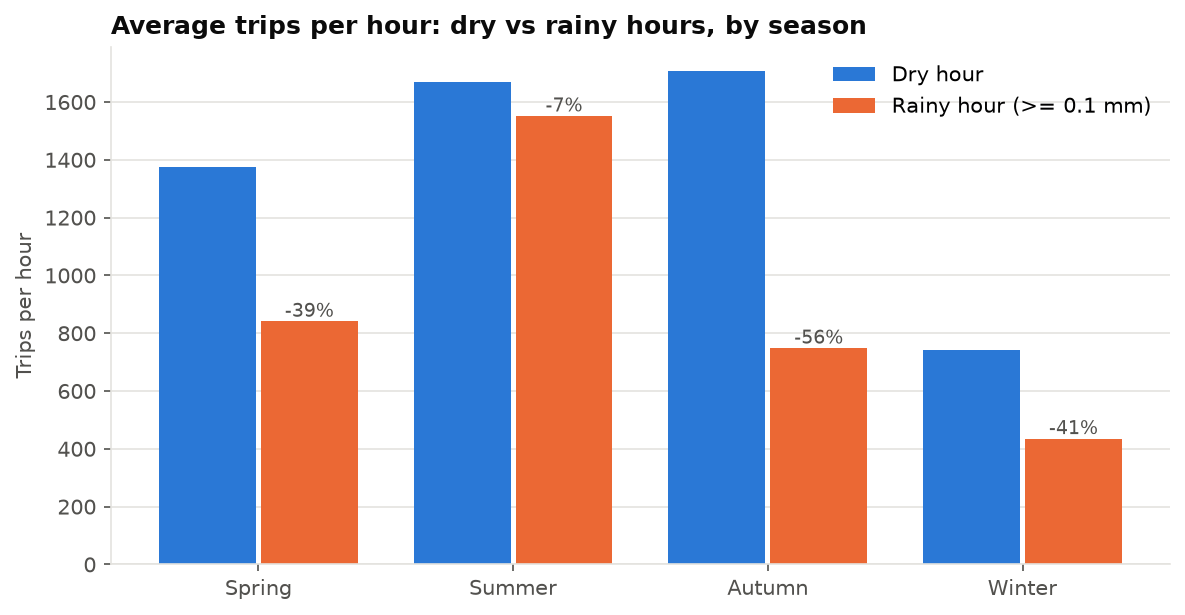

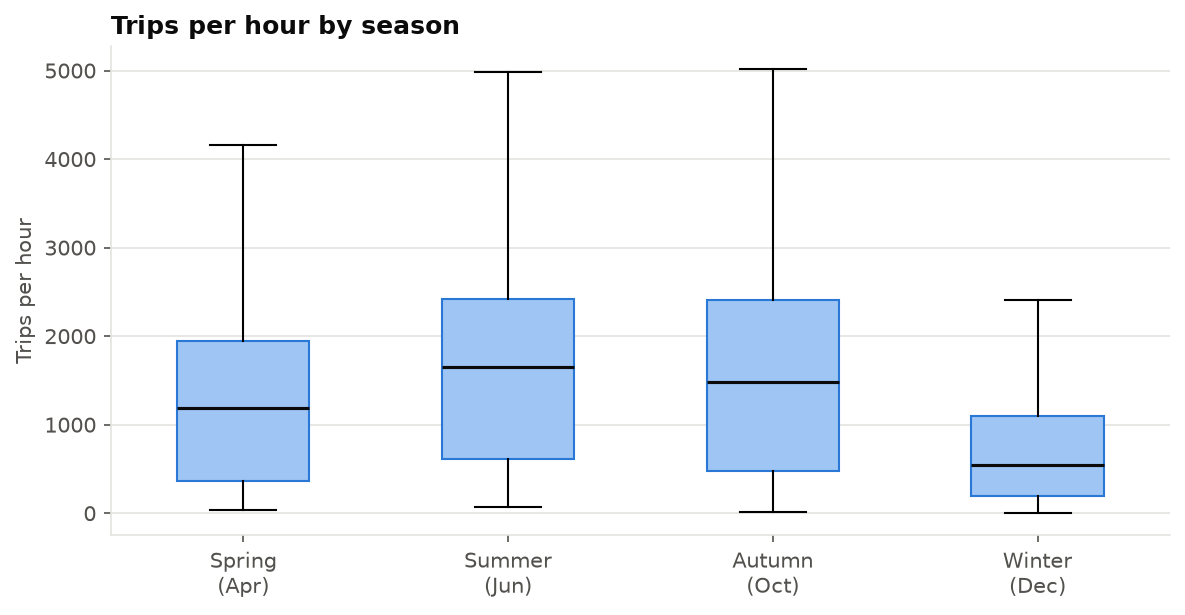

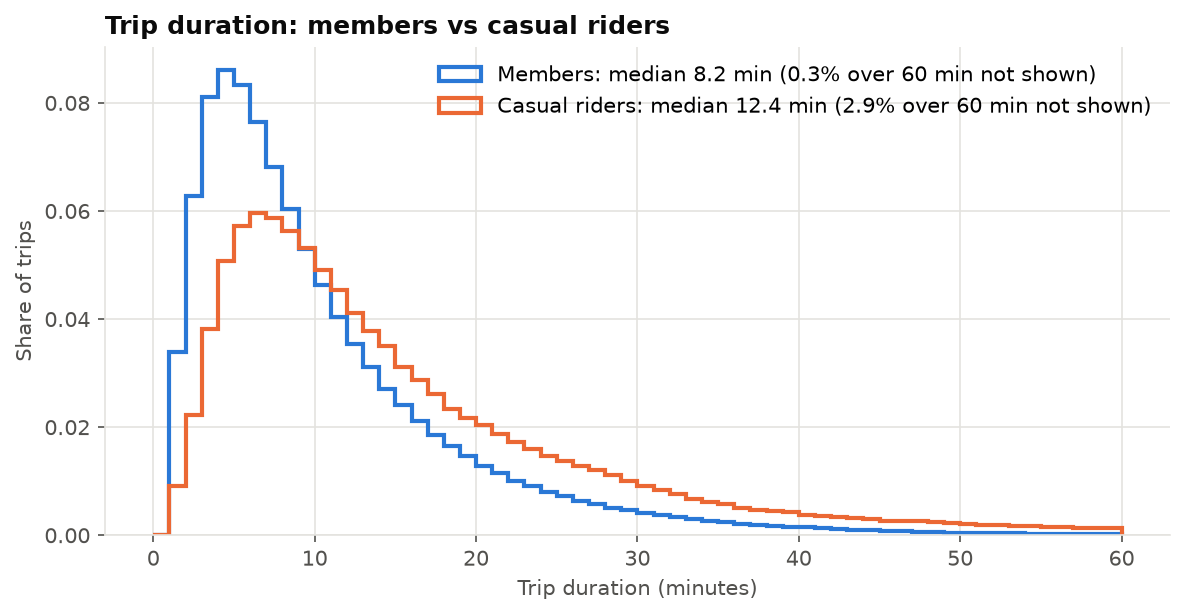

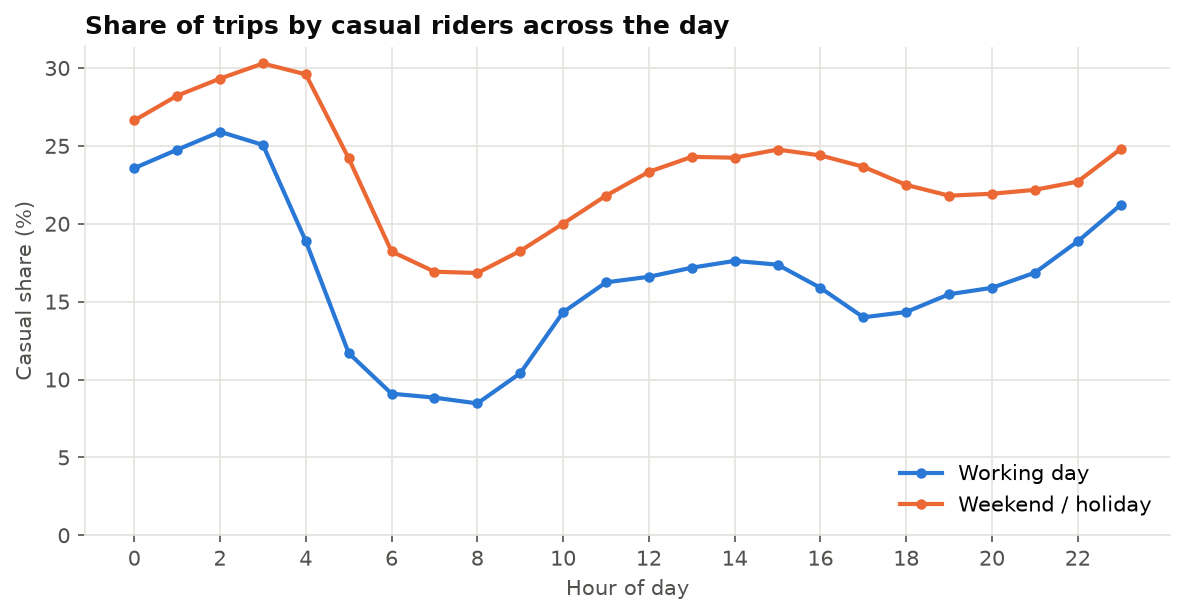

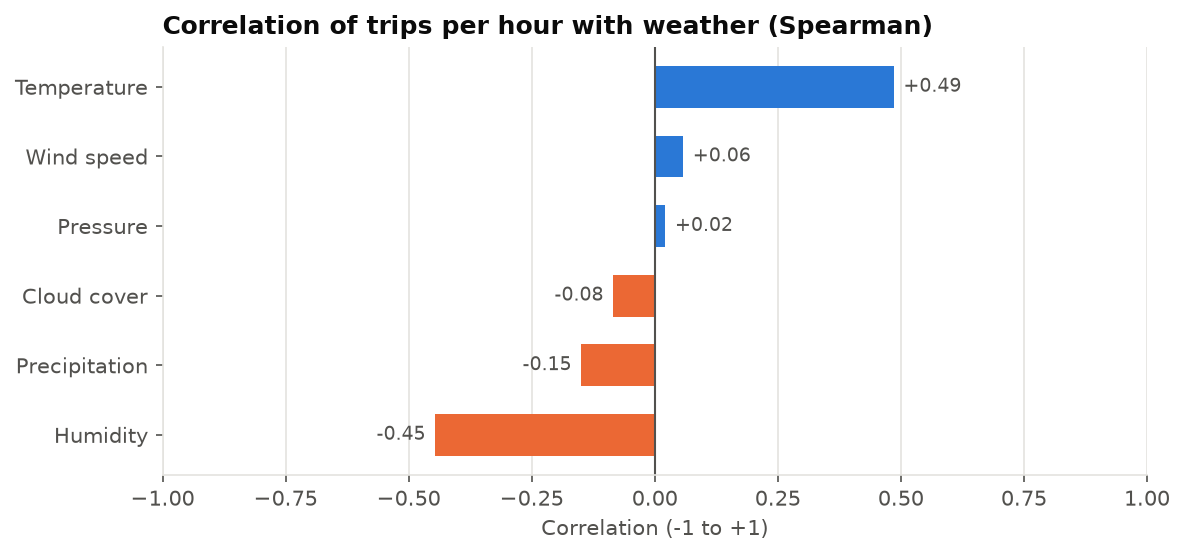

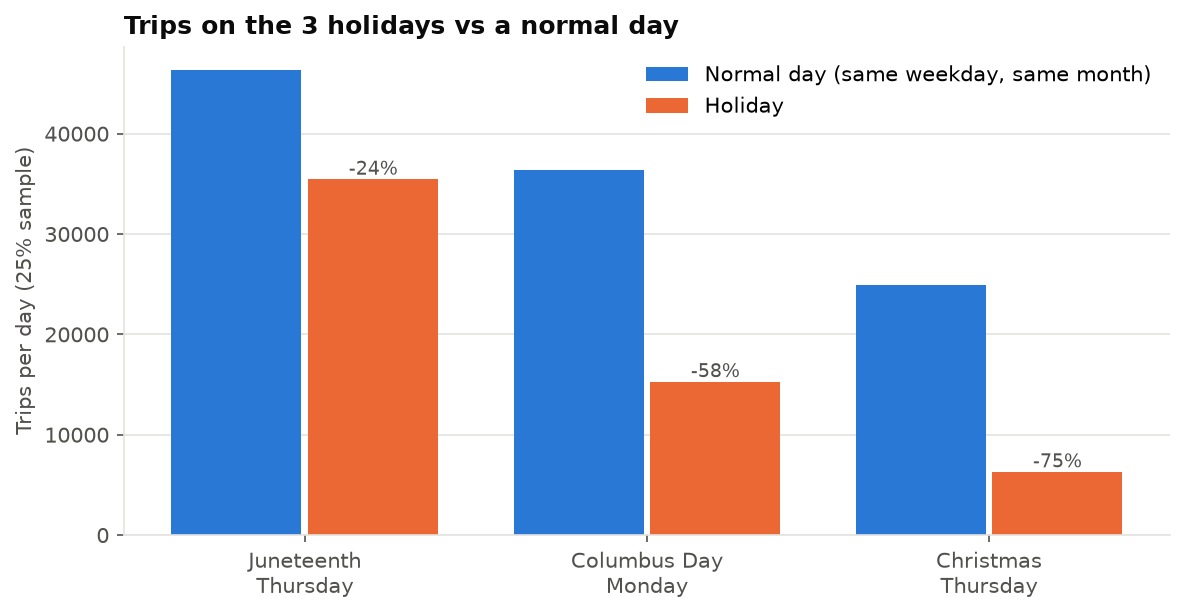

In [7]:
from IPython.display import Image, display

display(Image("outputs/figures/01_daily_profile_weekday_weekend.png", width=900))
display(Image("outputs/figures/02_trips_vs_temperature_member_casual.png", width=900))
display(Image("outputs/figures/03_rain_vs_dry_by_season.png", width=900))
display(Image("outputs/figures/04_hourly_demand_by_season.png", width=900))
display(Image("outputs/figures/05_trip_duration_member_casual.png", width=900))
display(Image("outputs/figures/06_casual_share_by_hour.png", width=900))
display(Image("outputs/figures/07_weather_correlations.png", width=900))
display(Image("outputs/figures/09_holidays_vs_normal_day.png", width=900))

## Part 3 - Test the hypotheses H1 to H5 with regression and statistical tests

From `stage2_tests.py`.

### Step 3.1 - Import libraries and helper functions for the tests

Libraries and two small helpers: `log` prints and records each result, and `pct` turns a regression coefficient on log(trips) into a percentage change.

In [8]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

OUT = "outputs"
C1, C2, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
lines = []


def log(msg=""):
    print(msg)
    lines.append(msg)


def pct(b):
    """Turn a regression coefficient on log(trips) into a % change."""
    return (np.exp(b) - 1) * 100

### Step 3.2 - Load the hourly table and take the log of trips

Load the hourly table and take log(trips + 1), so each regression effect reads as a % change.

In [9]:
hourly = pd.read_csv(os.path.join(OUT, "hourly_demand.csv"), parse_dates=["hour_ts"])
# log(trips + 1) so an hour with very few trips still works
for col in ["total_trips", "member_trips", "casual_trips"]:
    hourly["log_" + col] = np.log(hourly[col] + 1)

### Step 3.3 - Fit the main regression model and the robustness checks

Multiple regression of log(trips per hour) on temperature, rain, wind and humidity, holding hour of day x day type, day of week and month fixed. Newey-West (HAC) standard errors allow for neighbouring hours being similar. Fitted for all riders, members and casual riders, then refitted for each month and for working days only as robustness checks.

In [10]:
# the weather variables we test, and the calendar controls we hold fixed
# (is_non_working_day already includes holidays, so there is no separate holiday term)
WEATHER = "temp_c + is_raining + wind_speed_ms + humidity_pct"
CONTROLS = "C(hour) * is_non_working_day + C(day_of_week) + C(month)"


def fit(formula, data):
    """Ordinary least squares with Newey-West (HAC) standard errors."""
    model = smf.ols(formula, data=data)
    return model.fit(cov_type="HAC", cov_kwds={"maxlags": 24})


def effect(res, var):
    """% change in trips for one unit of var, with 95% confidence interval."""
    b = res.params[var]
    lo, hi = res.conf_int().loc[var]
    return pct(b), pct(lo), pct(hi)


log("== Main regression: log(trips per hour) on weather + calendar controls ==")
models = {"total": fit("log_total_trips ~ " + WEATHER + " + " + CONTROLS, hourly),
          "member": fit("log_member_trips ~ " + WEATHER + " + " + CONTROLS, hourly),
          "casual": fit("log_casual_trips ~ " + WEATHER + " + " + CONTROLS, hourly)}
rows = []
for name, res in models.items():
    log(f"\n{name.title()} trips: R-squared {res.rsquared:.3f}, hours {int(res.nobs)}")
    for var, label in [("temp_c", "per +1 C"), ("is_raining", "rainy hour"),
                       ("wind_speed_ms", "per +1 m/s wind"), ("humidity_pct", "per +1% humidity")]:
        e, lo, hi = effect(res, var)
        p = res.pvalues[var]
        log(f"  {label:<18} {e:+6.1f}%   95% CI [{lo:+.1f}%, {hi:+.1f}%]   p = {p:.3g}")
        rows.append({"riders": name, "variable": var, "effect_pct": e, "ci_low": lo, "ci_high": hi, "p": p})
pd.DataFrame(rows).to_csv(os.path.join(OUT, "regression_effects.csv"), index=False)

# robustness: same regression for total trips, one month at a time (month control dropped)
log("\nRobustness - total trips, each month separately:")
monthly = {}
for m, season in [(4, "April"), (6, "June"), (10, "October"), (12, "December")]:
    sub = hourly[hourly["month"] == m]
    # one month only, so there is no month control
    res = fit("log_total_trips ~ " + WEATHER + " + C(hour) * is_non_working_day + C(day_of_week)", sub)
    t = effect(res, "temp_c")
    r = effect(res, "is_raining")
    monthly[m] = (t, r)
    log(f"  {season:<9} temp {t[0]:+5.1f}% [{t[1]:+.1f}, {t[2]:+.1f}]   "
        f"rain {r[0]:+6.1f}% [{r[1]:+.1f}, {r[2]:+.1f}]")

# robustness: working days only
# working days only, so the day-type control is no longer needed
working_days = hourly[hourly["is_non_working_day"] == 0]
res_wd = fit("log_total_trips ~ " + WEATHER + " + C(hour) + C(day_of_week) + C(month)", working_days)
twd, rwd = effect(res_wd, "temp_c"), effect(res_wd, "is_raining")
log(f"  Working days only: temp {twd[0]:+.1f}% [{twd[1]:+.1f}, {twd[2]:+.1f}]   "
    f"rain {rwd[0]:+.1f}% [{rwd[1]:+.1f}, {rwd[2]:+.1f}]")


def verdict(ok_main, ok_robust):
    if ok_main and ok_robust:
        return "SUPPORTED"
    if ok_main or ok_robust:
        return "INCONCLUSIVE"
    return "NOT SUPPORTED"

== Main regression: log(trips per hour) on weather + calendar controls ==



Total trips: R-squared 0.930, hours 2928
  per +1 C             +2.5%   95% CI [+1.8%, +3.2%]   p = 1.64e-12
  rainy hour          -33.1%   95% CI [-40.9%, -24.2%]   p = 2.18e-10
  per +1 m/s wind      -3.7%   95% CI [-5.8%, -1.5%]   p = 0.00118
  per +1% humidity     -0.3%   95% CI [-0.6%, -0.1%]   p = 0.0121

Member trips: R-squared 0.934, hours 2928
  per +1 C             +2.1%   95% CI [+1.5%, +2.8%]   p = 1.53e-10
  rainy hour          -31.3%   95% CI [-39.2%, -22.4%]   p = 1.34e-09
  per +1 m/s wind      -3.5%   95% CI [-5.6%, -1.4%]   p = 0.00127
  per +1% humidity     -0.3%   95% CI [-0.5%, -0.0%]   p = 0.0219

Casual trips: R-squared 0.904, hours 2928
  per +1 C             +4.4%   95% CI [+3.4%, +5.3%]   p = 3.07e-20
  rainy hour          -39.9%   95% CI [-47.4%, -31.3%]   p = 8.01e-14
  per +1 m/s wind      -4.6%   95% CI [-7.2%, -1.9%]   p = 0.000897
  per +1% humidity     -0.5%   95% CI [-0.8%, -0.2%]   p = 0.000269

Robustness - total trips, each month separately:
  Apri

C:\Users\Harshit\AppData\Local\Temp\ipykernel_680\3869594533.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return model.fit(cov_type="HAC", cov_kwds={"maxlags": 24})


  October   temp  +2.2% [+1.7, +2.7]   rain  -42.3% [-50.5, -32.7]
  December  temp  +8.4% [+5.2, +11.8]   rain  -42.1% [-57.7, -20.7]
  Working days only: temp +1.9% [+1.3, +2.5]   rain -31.7% [-39.5, -23.0]


### Step 3.4 - Test H1: does warmer weather mean more trips?

**H1** Warmer hours have more trips.

In [11]:
log("\n== H1: warmer hours have more trips ==")
rho, p = stats.spearmanr(hourly["temp_c"], hourly["total_trips"])
log(f"  Spearman correlation (raw): rho = {rho:+.2f}, p = {p:.3g}")
t = effect(models["total"], "temp_c")
log(f"  Regression: {t[0]:+.1f}% trips per +1 C, 95% CI [{t[1]:+.1f}%, {t[2]:+.1f}%]")
h1 = verdict(t[1] > 0, all(monthly[m][0][1] > 0 for m in monthly) and twd[1] > 0)
log(f"  Verdict H1: {h1}")


== H1: warmer hours have more trips ==
  Spearman correlation (raw): rho = +0.49, p = 1.05e-172
  Regression: +2.5% trips per +1 C, 95% CI [+1.8%, +3.2%]
  Verdict H1: SUPPORTED


### Step 3.5 - Test H2: does rain mean fewer trips at similar temperatures?

**H2** Rainy hours have fewer trips than dry hours at similar temperatures.

In [12]:
log("\n== H2: rainy hours have fewer trips than dry hours at similar temperatures ==")
wet = hourly.loc[hourly["is_raining"] == 1, "total_trips"]
dry = hourly.loc[hourly["is_raining"] == 0, "total_trips"]
tt = stats.ttest_ind(wet, dry, equal_var=False)
mw = stats.mannwhitneyu(wet, dry, alternative="two-sided")
rbc = 1 - 2 * mw.statistic / (len(wet) * len(dry))  # rank-biserial: >0 means dry hours busier
log(f"  Raw means: rainy {wet.mean():.0f} vs dry {dry.mean():.0f} trips per hour")
log(f"  Welch t-test: t = {tt.statistic:.2f}, p = {tt.pvalue:.3g}")
log(f"  Mann-Whitney U: p = {mw.pvalue:.3g}, rank-biserial r = {rbc:+.2f}")
r = effect(models["total"], "is_raining")
log(f"  Regression (temperature, time and day held fixed): rain {r[0]:+.1f}%, "
    f"95% CI [{r[1]:+.1f}%, {r[2]:+.1f}%]")
h2 = verdict(r[2] < 0, all(monthly[m][1][2] < 0 for m in monthly) and rwd[2] < 0)
log(f"  Verdict H2: {h2}")


== H2: rainy hours have fewer trips than dry hours at similar temperatures ==
  Raw means: rainy 936 vs dry 1367 trips per hour
  Welch t-test: t = -9.18, p = 5.02e-19
  Mann-Whitney U: p = 2.06e-14, rank-biserial r = +0.23
  Regression (temperature, time and day held fixed): rain -33.1%, 95% CI [-40.9%, -24.2%]
  Verdict H2: SUPPORTED


### Step 3.6 - Test H3: are casual riders more weather-sensitive than members?

**H3** Casual riders are more weather-sensitive than members: do their 95% confidence intervals separate from the members'?

In [13]:
log("\n== H3: casual riders are more weather-sensitive than members ==")
for var, label in [("temp_c", "per +1 C"), ("is_raining", "rainy hour")]:
    m_e, c_e = effect(models["member"], var), effect(models["casual"], var)
    log(f"  {label:<11} members {m_e[0]:+.1f}% [{m_e[1]:+.1f}, {m_e[2]:+.1f}]   "
        f"casual {c_e[0]:+.1f}% [{c_e[1]:+.1f}, {c_e[2]:+.1f}]")
mt, ct = effect(models["member"], "temp_c"), effect(models["casual"], "temp_c")
mr, cr = effect(models["member"], "is_raining"), effect(models["casual"], "is_raining")
temp_stronger = ct[1] > mt[2]      # casual CI entirely above member CI
rain_stronger = cr[2] < mr[1]      # casual CI entirely below member CI
log(f"  Casual temperature effect clearly larger (CIs do not overlap): {temp_stronger}")
log(f"  Casual rain effect clearly larger (CIs do not overlap): {rain_stronger}")
h3 = verdict(temp_stronger, rain_stronger)
log(f"  Verdict H3: {h3}")


== H3: casual riders are more weather-sensitive than members ==
  per +1 C    members +2.1% [+1.5, +2.8]   casual +4.4% [+3.4, +5.3]
  rainy hour  members -31.3% [-39.2, -22.4]   casual -39.9% [-47.4, -31.3]
  Casual temperature effect clearly larger (CIs do not overlap): True
  Casual rain effect clearly larger (CIs do not overlap): False
  Verdict H3: INCONCLUSIVE


### Step 3.7 - Test H4: are casual trips longer than member trips?

**H4** Casual trips are longer than member trips (tested on individual trips).

In [14]:
log("\n== H4: casual trips are longer than member trips (trip level) ==")
trips = pd.read_parquet("ssot.parquet", columns=["member_casual", "duration_min", "is_non_working_day"])
cas = trips.loc[trips["member_casual"] == "casual", "duration_min"]
mem = trips.loc[trips["member_casual"] == "member", "duration_min"]
mw4 = stats.mannwhitneyu(cas, mem, alternative="greater")
rbc4 = 2 * mw4.statistic / (len(cas) * len(mem)) - 1  # >0 means casual trips longer
pooled = np.sqrt(((len(cas) - 1) * cas.var() + (len(mem) - 1) * mem.var()) / (len(cas) + len(mem) - 2))
d4 = (cas.mean() - mem.mean()) / pooled
log(f"  Median: casual {cas.median():.1f} min vs member {mem.median():.1f} min")
log(f"  Mean:   casual {cas.mean():.1f} min vs member {mem.mean():.1f} min")
log(f"  Mann-Whitney U (casual > member): p = {mw4.pvalue:.3g}, rank-biserial r = {rbc4:+.2f}")
log(f"  Cohen's d = {d4:.2f}")
wd = trips[trips["is_non_working_day"] == 0]
wd_c = wd.loc[wd["member_casual"] == "casual", "duration_min"].median()
wd_m = wd.loc[wd["member_casual"] == "member", "duration_min"].median()
log(f"  Robustness, working days only: median casual {wd_c:.1f} vs member {wd_m:.1f} min")
h4 = verdict(mw4.pvalue < 0.05 and rbc4 > 0, wd_c > wd_m)
log(f"  Verdict H4: {h4}")
del trips


== H4: casual trips are longer than member trips (trip level) ==


  Median: casual 12.4 min vs member 8.2 min
  Mean:   casual 17.4 min vs member 10.8 min
  Mann-Whitney U (casual > member): p = 0, rank-biserial r = +0.30
  Cohen's d = 0.60
  Robustness, working days only: median casual 11.7 vs member 8.1 min
  Verdict H4: SUPPORTED


### Step 3.8 - Test H5: do weekends have weaker commute peaks and more casual riders?

**H5** Weekends have weaker commute peaks and a higher casual share.

In [15]:
log("\n== H5: weekends have weaker commute peaks and a higher casual share ==")
# (a) peak strength = trips at 8 am and 5-6 pm divided by the average trips 10 am-3 pm
day_type = {0: "working", 1: "non-working"}
peak = {}
for k, name in day_type.items():
    h = hourly[hourly["is_non_working_day"] == k].groupby("hour")["total_trips"].mean()
    peak[name] = h[[8, 17, 18]].mean() / h[10:15].mean()
    log(f"  Peak ratio ({name} days): {peak[name]:.2f}  (1.0 = no commute peak)")
rush = hourly[hourly["hour"].isin([8, 17, 18])]
mw5 = stats.mannwhitneyu(rush.loc[rush["is_non_working_day"] == 0, "total_trips"],
                         rush.loc[rush["is_non_working_day"] == 1, "total_trips"], alternative="greater")
log(f"  Mann-Whitney, trips at 8 am / 5-6 pm, working > non-working: p = {mw5.pvalue:.3g}")
# (b) casual share: chi-square on the counts of member/casual trips by day type
table = hourly.groupby("is_non_working_day")[["member_trips", "casual_trips"]].sum()
chi2, p_chi, _, _ = stats.chi2_contingency(table.values)
cramers_v = np.sqrt(chi2 / table.values.sum())  # 2x2 table, so min(r, c) - 1 = 1
share = table["casual_trips"] / table.sum(axis=1)
log(f"  Casual share: working {share[0]:.1%} vs non-working {share[1]:.1%}")
log(f"  Chi-square: chi2 = {chi2:,.0f}, p = {p_chi:.3g}, Cramer's V = {cramers_v:.3f}")
h5 = verdict(peak["non-working"] < peak["working"] and mw5.pvalue < 0.05,
             share[1] > share[0] and p_chi < 0.05)
log(f"  Verdict H5: {h5}")


== H5: weekends have weaker commute peaks and a higher casual share ==
  Peak ratio (working days): 2.00  (1.0 = no commute peak)
  Peak ratio (non-working days): 0.84  (1.0 = no commute peak)
  Mann-Whitney, trips at 8 am / 5-6 pm, working > non-working: p = 2.18e-22
  Casual share: working 14.8% vs non-working 23.0%
  Chi-square: chi2 = 34,954, p = 0, Cramer's V = 0.096
  Verdict H5: SUPPORTED


### Step 3.9 - Test the season effect across spring, summer, autumn and winter

Kruskal-Wallis test across the four seasons, with epsilon-squared as the effect size.

In [16]:
log("\n== Season effect: does hourly demand differ between the four seasons? ==")
groups = [g["total_trips"].values for _, g in hourly.groupby("season")]
kw = stats.kruskal(*groups)
eps2 = (kw.statistic - len(groups) + 1) / (len(hourly) - len(groups))  # epsilon-squared
log(f"  Median trips per hour: {hourly.groupby('season')['total_trips'].median().to_dict()}")
log(f"  Kruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.3g}, epsilon-squared = {eps2:.3f}")


== Season effect: does hourly demand differ between the four seasons? ==
  Median trips per hour: {'autumn': 1485.0, 'spring': 1193.0, 'summer': 1648.5, 'winter': 549.5}
  Kruskal-Wallis: H = 354.1, p = 1.95e-76, epsilon-squared = 0.120


### Step 3.10 - Summary of all hypothesis verdicts

All verdicts in one place; also saved to `outputs/test_results.txt`.

In [17]:
log("\n== Summary of verdicts ==")
for h, v in [("H1 warmer -> more trips", h1), ("H2 rain -> fewer trips", h2),
             ("H3 casual more weather-sensitive", h3), ("H4 casual trips longer", h4),
             ("H5 weekends: weaker peaks, more casual", h5)]:
    log(f"  {h:<40} {v}")

with open(os.path.join(OUT, "test_results.txt"), "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines))


== Summary of verdicts ==
  H1 warmer -> more trips                  SUPPORTED
  H2 rain -> fewer trips                   SUPPORTED
  H3 casual more weather-sensitive         INCONCLUSIVE
  H4 casual trips longer                   SUPPORTED
  H5 weekends: weaker peaks, more casual   SUPPORTED


### Step 3.11 - Chart: weather effects for members vs casual riders

Chart of the temperature and rain effects for members and casual riders, with their 95% confidence intervals.


Saved outputs/test_results.txt, outputs/regression_effects.csv and chart 08.


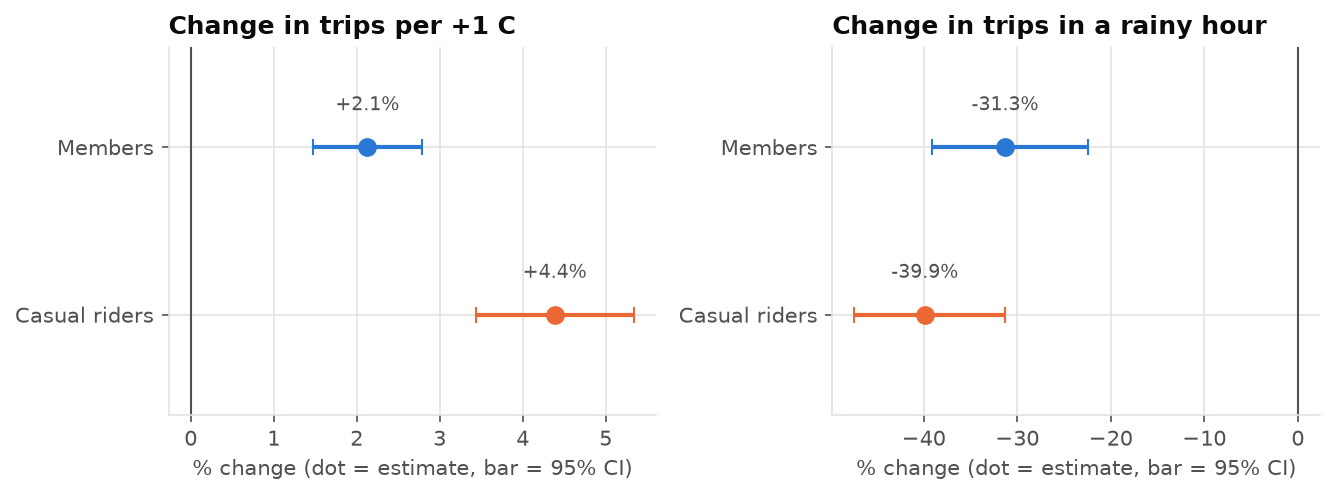

In [18]:
eff = pd.DataFrame(rows)
eff = eff[eff["riders"].isin(["member", "casual"]) & eff["variable"].isin(["temp_c", "is_raining"])]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, var, title in [(axes[0], "temp_c", "Change in trips per +1 C"),
                       (axes[1], "is_raining", "Change in trips in a rainy hour")]:
    # one dot per rider type: the estimate, with a bar for its 95% confidence interval
    for y, who, color in [(1, "member", C1), (0, "casual", C2)]:
        row = eff[(eff["variable"] == var) & (eff["riders"] == who)].iloc[0]
        left = row["effect_pct"] - row["ci_low"]
        right = row["ci_high"] - row["effect_pct"]
        ax.errorbar(row["effect_pct"], y, xerr=[[left], [right]], fmt="o", ms=8, color=color, capsize=4, lw=2)
        ax.text(row["effect_pct"], y + 0.22, f"{row['effect_pct']:+.1f}%", ha="center", fontsize=9, color=INK2)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_title(title, loc="left", fontweight="bold", color=INK)
    ax.set(yticks=[1, 0], yticklabels=["Members", "Casual riders"], ylim=(-0.6, 1.6),
           xlabel="% change (dot = estimate, bar = 95% CI)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "08_weather_effects_member_casual.png"), dpi=150,
            bbox_inches="tight", facecolor="white")
print("\nSaved outputs/test_results.txt, outputs/regression_effects.csv and chart 08.")

**Charts produced in this part** (saved in `outputs/figures`):

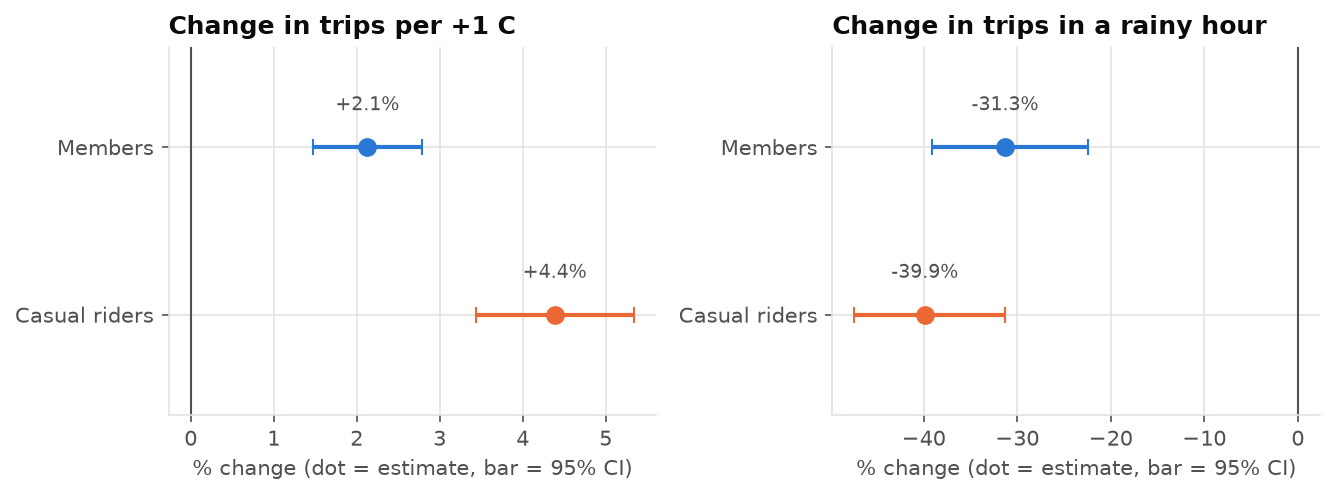

In [19]:
from IPython.display import Image, display

display(Image("outputs/figures/08_weather_effects_member_casual.png", width=900))

## Part 4 - Check the findings with machine learning (gradient boosting + SHAP)

From `stage2_model.py`.

### Step 4.1 - Import machine-learning libraries

Libraries for the machine-learning check: gradient boosting (scikit-learn) and SHAP.

In [20]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

OUT = "outputs"
C1, C2, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
lines = []


def log(msg=""):
    print(msg)
    lines.append(msg)

### Step 4.2 - Choose features and split into training and test days

Features and a time-based split: the last 7 days of every month are the test set, so the model is judged on days it never saw.

In [21]:
hourly = pd.read_csv(os.path.join(OUT, "hourly_demand.csv"), parse_dates=["hour_ts"])
FEATURES = ["temp_c", "is_raining", "precip_mm", "wind_speed_ms", "humidity_pct", "cloud_cover_pct",
            "hour", "day_of_week", "is_non_working_day", "month"]
NAMES = {"temp_c": "Temperature", "is_raining": "Rain (yes/no)", "precip_mm": "Rain amount",
         "wind_speed_ms": "Wind speed", "humidity_pct": "Humidity", "cloud_cover_pct": "Cloud cover",
         "hour": "Hour of day", "day_of_week": "Day of week", "is_non_working_day": "Weekend/holiday",
         "month": "Month"}

# Time-based split: the last 7 days of every month are the test set, so the model is
# checked on days it has never seen (a random split would leak neighbouring hours).
day_of_month = hourly["hour_ts"].dt.day
days_in_month = hourly["hour_ts"].dt.days_in_month
test = day_of_month > days_in_month - 7
X_train, X_test = hourly.loc[~test, FEATURES], hourly.loc[test, FEATURES]
y_train, y_test = hourly.loc[~test, "total_trips"], hourly.loc[test, "total_trips"]
log(f"Training hours: {len(X_train):,}   test hours (last 7 days of each month): {len(X_test):,}")

Training hours: 2,256   test hours (last 7 days of each month): 672


### Step 4.3 - Train the gradient boosting model and compare with a baseline

Train the gradient boosting model and compare it with a simple baseline (the average for that hour and day type).

In [22]:
model = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                  subsample=0.8, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

# Baseline to beat: the average for that hour of day and day type in the training data
base = hourly.loc[~test].groupby(["hour", "is_non_working_day"])["total_trips"].mean()
base_pred = X_test.set_index(["hour", "is_non_working_day"]).index.map(base)

log("\n== How well does it predict unseen days? ==")
log(f"  Gradient boosting: R-squared {r2_score(y_test, pred):.3f}, "
    f"mean absolute error {mean_absolute_error(y_test, pred):.0f} trips per hour")
log(f"  Baseline (hour + day type average): R-squared {r2_score(y_test, base_pred):.3f}, "
    f"mean absolute error {mean_absolute_error(y_test, base_pred):.0f} trips per hour")


== How well does it predict unseen days? ==
  Gradient boosting: R-squared 0.893, mean absolute error 246 trips per hour
  Baseline (hour + day type average): R-squared 0.601, mean absolute error 492 trips per hour


### Step 4.4 - Explain the model with SHAP and check it agrees with the regression

SHAP splits each prediction into how much each feature pushed it up or down. We check that the model agrees with the regression on direction: warmer up, rain down.

In [23]:
# SHAP splits each prediction into how much each feature pushed it up or down.
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).rename(NAMES).sort_values()

log("\n== Which features matter most? (mean |SHAP|, trips per hour) ==")
for name, v in importance.sort_values(ascending=False).items():
    log(f"  {name:<16} {v:6.0f}")

# direction check: does a higher temperature push predictions up, and rain push them down?
sv = pd.DataFrame(shap_values, columns=FEATURES, index=X_test.index)
temp_dir = np.corrcoef(X_test["temp_c"], sv["temp_c"])[0, 1]
# rain is split over two features (yes/no and amount), so add their SHAP values together
sv["rain_total"] = sv["is_raining"] + sv["precip_mm"]
rain_effect = sv.loc[X_test["is_raining"] == 1, "rain_total"].mean()
rainy_pred = pred[X_test["is_raining"].values == 1].mean()
log("\n== Do the directions agree with the regression? ==")
log(f"  Temperature: correlation between temperature and its SHAP value = {temp_dir:+.2f} "
    f"(positive = warmer pushes demand up)")
log(f"  Rain: in rainy hours, the two rain features change the prediction by {rain_effect:+.0f} trips per hour "
    f"(about {rain_effect / (rainy_pred - rain_effect) * 100:+.0f}% of what the model would predict without rain)")

with open(os.path.join(OUT, "model_results.txt"), "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines))


== Which features matter most? (mean |SHAP|, trips per hour) ==
  Hour of day         662
  Temperature         306
  Humidity             88
  Weekend/holiday      80
  Month                68
  Day of week          58
  Wind speed           53
  Rain amount          39
  Cloud cover          25
  Rain (yes/no)        10

== Do the directions agree with the regression? ==
  Temperature: correlation between temperature and its SHAP value = +0.90 (positive = warmer pushes demand up)
  Rain: in rainy hours, the two rain features change the prediction by -202 trips per hour (about -17% of what the model would predict without rain)


### Step 4.5 - Draw the SHAP charts

SHAP importance and the temperature and rain effects.

In [24]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(importance.index, importance.values, color=C1, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 5, i, f"{v:.0f}", va="center", fontsize=9, color=INK2)
ax.set_title("What drives the model's predictions (mean |SHAP|)", loc="left", fontweight="bold", color=INK)
ax.set_xlabel("Average effect on predicted trips per hour")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "10_shap_importance.png"), dpi=150, facecolor="white")
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_test["temp_c"], sv["temp_c"], s=6, color=C1, alpha=0.4, lw=0)
axes[0].set(xlabel="Temperature (C)", ylabel="SHAP value (trips per hour)")
axes[0].set_title("Temperature: warmer pushes demand up", loc="left", fontweight="bold", color=INK)
groups = [sv.loc[X_test["is_raining"] == 0, "rain_total"], sv.loc[X_test["is_raining"] == 1, "rain_total"]]
axes[1].boxplot(groups, widths=0.5, showfliers=False, medianprops=dict(color=INK))
axes[1].set_xticks([1, 2], ["Dry hour", "Rainy hour"])
axes[1].set_ylabel("SHAP value of rain features (trips per hour)")
axes[1].set_title("Rain: pushes demand down", loc="left", fontweight="bold", color=INK)
for ax in axes:
    ax.axhline(0, color=INK2, lw=1)
    ax.grid(color=GRID)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "11_shap_temperature_rain.png"), dpi=150, facecolor="white")
plt.close(fig)
print("\nSaved outputs/model_results.txt and charts 10-11.")


Saved outputs/model_results.txt and charts 10-11.


**Charts produced in this part** (saved in `outputs/figures`):

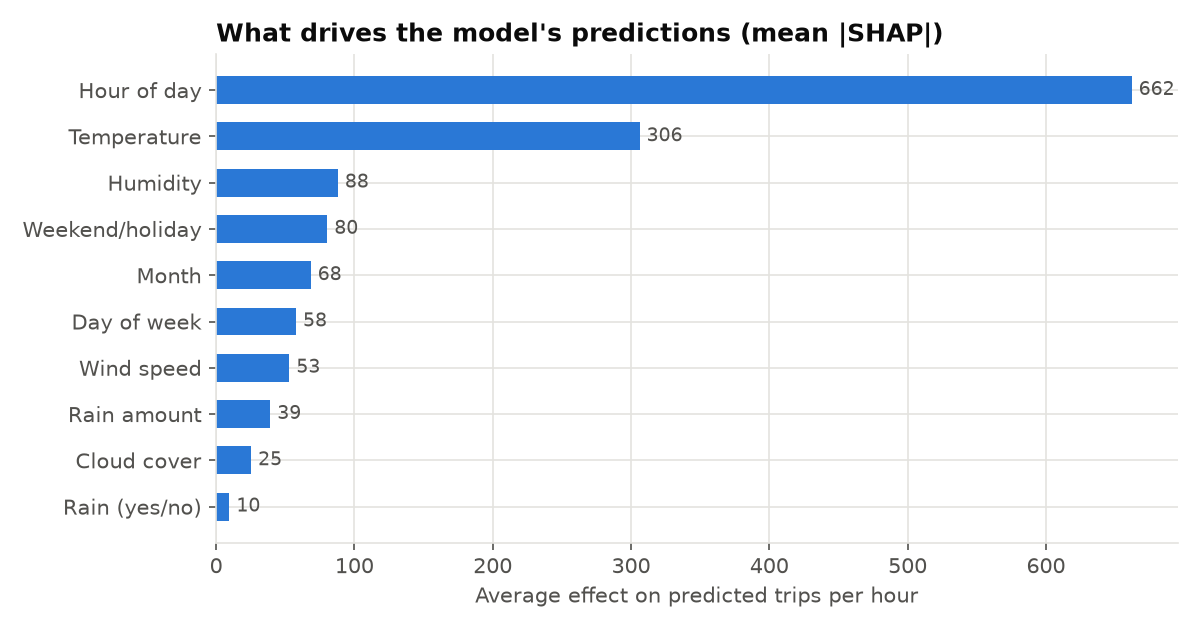

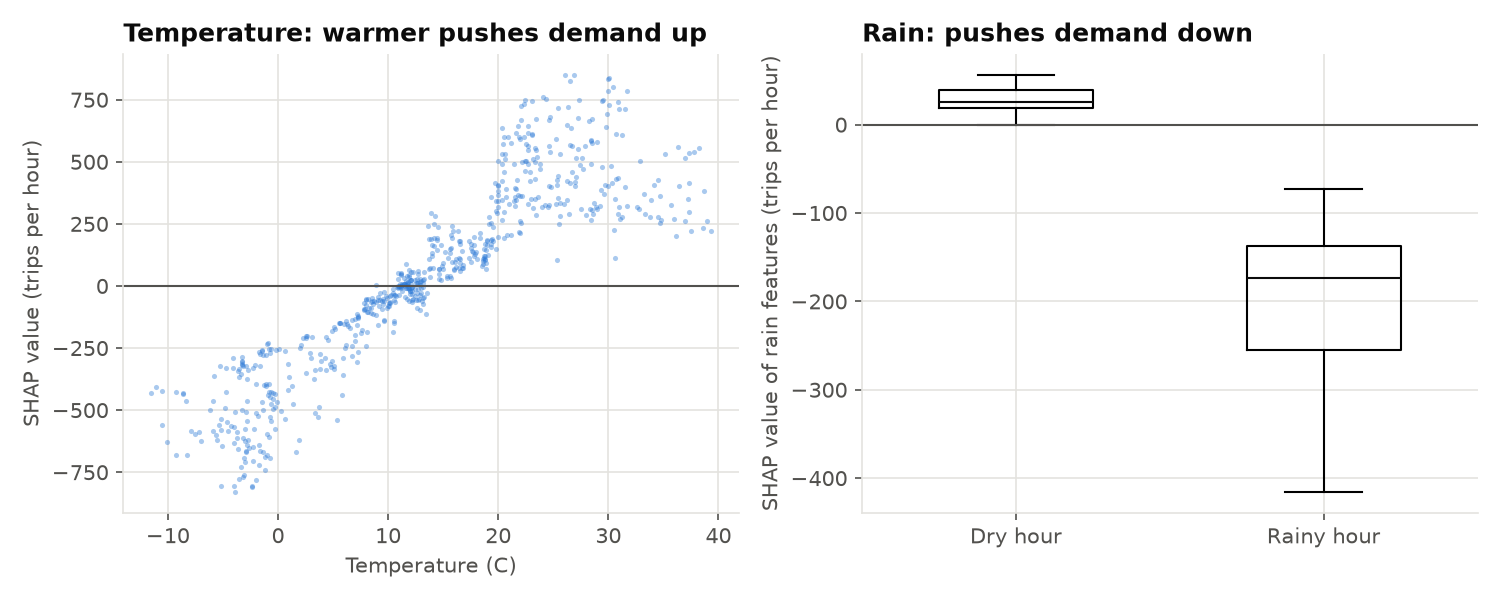

In [25]:
from IPython.display import Image, display

display(Image("outputs/figures/10_shap_importance.png", width=900))
display(Image("outputs/figures/11_shap_temperature_rain.png", width=900))

## Part 5 - Turn the results into decisions for the rebalancing team

From `stage3_decisions.py`.

### Step 5.1 - Import libraries and set the sample scale (x4)

Stage 3 settings. Our data is a 25% sample, so whole-system numbers are multiplied by 4.

In [26]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

OUT = "outputs"
SCALE = 4  # our data is a 25% sample, so multiply by 4 for the whole system
C1, C2, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
lines = []


def log(msg=""):
    print(msg)
    lines.append(msg)

### Step 5.2 - Estimate demand for typical weather and times

Expected trips per hour for the whole system under typical weather and times, from the same regression as the hypothesis tests.

In [27]:
hourly = pd.read_csv(os.path.join(OUT, "hourly_demand.csv"), parse_dates=["hour_ts"])
for col in ["member_trips", "casual_trips"]:
    hourly["log_" + col] = np.log(hourly[col] + 1)

# same regression as stage2_tests.py, so the numbers match the hypothesis results
WEATHER = "temp_c + is_raining + wind_speed_ms + humidity_pct"
CONTROLS = "C(hour) * is_non_working_day + C(day_of_week) + C(month)"
members = smf.ols("log_member_trips ~ " + WEATHER + " + " + CONTROLS, data=hourly).fit()
casual = smf.ols("log_casual_trips ~ " + WEATHER + " + " + CONTROLS, data=hourly).fit()

# typical conditions; wind and humidity are set to their usual values for each case
weather = {
    "Warm & dry (25 C)": dict(temp_c=25, is_raining=0, humidity_pct=60, wind_speed_ms=3, month=6),
    "Mild & dry (12 C)": dict(temp_c=12, is_raining=0, humidity_pct=65, wind_speed_ms=3.5, month=4),
    "Mild & rainy (12 C)": dict(temp_c=12, is_raining=1, humidity_pct=90, wind_speed_ms=4.5, month=4),
    "Cold & dry (0 C)": dict(temp_c=0, is_raining=0, humidity_pct=60, wind_speed_ms=4, month=12),
}
moments = {
    "Weekday 8 am": dict(hour=8, is_non_working_day=0, day_of_week=2),
    "Weekday 5 pm": dict(hour=17, is_non_working_day=0, day_of_week=2),
    "Weekend 2 pm": dict(hour=14, is_non_working_day=1, day_of_week=5),
}
rows = []
for w_name, w in weather.items():
    for m_name, m in moments.items():
        case = pd.DataFrame([{**w, **m}])
        mem = (np.exp(members.predict(case)[0]) - 1) * SCALE
        cas = (np.exp(casual.predict(case)[0]) - 1) * SCALE
        rows.append({"weather": w_name, "moment": m_name, "member_trips": round(mem),
                     "casual_trips": round(cas), "total_trips": round(mem + cas),
                     "casual_share_pct": round(cas / (mem + cas) * 100, 1)})
scen = pd.DataFrame(rows)
scen.to_csv(os.path.join(OUT, "demand_scenarios.csv"), index=False)

log("== Expected trips per hour, whole system (sample x 4) ==")
table = scen.pivot(index="weather", columns="moment", values="total_trips").loc[list(weather), list(moments)]
log(table.to_string())
log("\nCasual share (%):")
log(scen.pivot(index="weather", columns="moment", values="casual_share_pct").loc[list(weather), list(moments)].to_string())

warm_we = table.loc["Warm & dry (25 C)", "Weekend 2 pm"]
cold_we = table.loc["Cold & dry (0 C)", "Weekend 2 pm"]
dry_am = table.loc["Mild & dry (12 C)", "Weekday 8 am"]
wet_am = table.loc["Mild & rainy (12 C)", "Weekday 8 am"]
log(f"\nWeekend 2 pm: warm & dry {warm_we:,} vs cold & dry {cold_we:,} trips per hour "
    f"({warm_we / cold_we:.1f}x as many)")
log(f"Weekday 8 am at 12 C: rainy {wet_am:,} vs dry {dry_am:,} trips per hour "
    f"({(wet_am / dry_am - 1) * 100:+.0f}%)")

# chart: grouped bars, one group per weather, one bar per moment (colours = moments)
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(weather))
colors = [C1, C2, "#1baf7a"]
for i, (m_name, color) in enumerate(zip(moments, colors)):
    vals = table[m_name].values
    ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=color, label=m_name)
ax.set_title("Expected trips per hour across the whole system, by weather and time",
             loc="left", fontweight="bold", color=INK)
ax.set(xticks=x, xticklabels=list(weather), ylabel="Trips per hour (whole system)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "12_demand_scenarios.png"), dpi=150, facecolor="white")
plt.close(fig)

== Expected trips per hour, whole system (sample x 4) ==
moment               Weekday 8 am  Weekday 5 pm  Weekend 2 pm
weather                                                      
Warm & dry (25 C)           15744         17857         11895
Mild & dry (12 C)           10411         11678          7511
Mild & rainy (12 C)          6328          7060          4461
Cold & dry (0 C)             5922          6583          4108

Casual share (%):
moment               Weekday 8 am  Weekday 5 pm  Weekend 2 pm
weather                                                      
Warm & dry (25 C)            11.5          15.2          26.6
Mild & dry (12 C)             8.4          11.3          20.6
Mild & rainy (12 C)           7.0           9.4          17.4
Cold & dry (0 C)              6.0           8.1          15.2

Weekend 2 pm: warm & dry 11,895 vs cold & dry 4,108 trips per hour (2.9x as many)
Weekday 8 am at 12 C: rainy 6,328 vs dry 10,411 trips per hour (-39%)


### Step 5.3 - Find the stations that empty or fill fastest each morning

Which stations empty or fill fastest on working-day mornings (7-10 am): the stations the rebalancing team should serve first.

In [28]:
trips = pd.read_parquet("ssot.parquet", columns=["start_station_id", "start_station_name", "end_station_id",
                                                 "hour", "is_non_working_day", "start_station_capacity"])
trips["start_station_id"] = trips["start_station_id"].astype(str)
trips["end_station_id"] = trips["end_station_id"].astype(str)
n_days = hourly.loc[hourly["is_non_working_day"] == 0, "date"].nunique()

# working-day mornings (7-10 am): bikes leaving vs bikes arriving at each station
am = trips[(trips["is_non_working_day"] == 0) & trips["hour"].isin([7, 8, 9])]
leaving = am.groupby("start_station_id").size()
arriving = am.groupby("end_station_id").size()
flow = pd.DataFrame({"leaving": leaving, "arriving": arriving}).fillna(0)
# per morning, whole system: net bikes lost (positive = station empties)
flow["net_bikes_lost_per_morning"] = (flow["leaving"] - flow["arriving"]) * SCALE / n_days

info = (trips.groupby("start_station_id")
        .agg(name=("start_station_name", "first"), capacity=("start_station_capacity", "first"),
             trips_total=("start_station_name", "size")))
st = info.join(flow, how="left").fillna({"net_bikes_lost_per_morning": 0})
st["trips_per_day"] = (st["trips_total"] * SCALE / hourly["date"].nunique()).round()
# a station is a top priority if it loses more bikes in one morning than it can hold
st["lost_vs_capacity_pct"] = (st["net_bikes_lost_per_morning"] / st["capacity"] * 100).round()
st = st.sort_values("net_bikes_lost_per_morning", ascending=False)
cols = ["name", "capacity", "trips_per_day", "net_bikes_lost_per_morning", "lost_vs_capacity_pct"]
st[cols].round(1).to_csv(os.path.join(OUT, "station_priority.csv"))

log("\n== Stations that empty fastest on working-day mornings (7-10 am), whole system ==")
top = st[cols].head(10).copy()
top["net_bikes_lost_per_morning"] = top["net_bikes_lost_per_morning"].round()
log(top.to_string())
log(f"\nStations losing at least half their capacity in one morning: "
    f"{(st['lost_vs_capacity_pct'] >= 50).sum()}")
fill = st.sort_values("net_bikes_lost_per_morning").head(10)[cols].copy()
fill["net_bikes_lost_per_morning"] = fill["net_bikes_lost_per_morning"].round()
log("\n== Stations that fill fastest on working-day mornings (negative = more bikes arrive) ==")
log(fill.to_string())

with open(os.path.join(OUT, "stage3_results.txt"), "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines))
print("\nSaved demand_scenarios.csv, station_priority.csv, stage3_results.txt and chart 12.")


== Stations that empty fastest on working-day mornings (7-10 am), whole system ==
                                               name  capacity  trips_per_day  net_bikes_lost_per_morning  lost_vs_capacity_pct
start_station_id                                                                                                              
6756.01                            W 43 St & 10 Ave     117.0          278.0                        60.0                  51.0
6230.04                         FDR Drive & E 35 St     123.0          189.0                        46.0                  38.0
5335.07           Grand St & Samuel Dickstein Plaza      81.0          140.0                        44.0                  54.0
7183.03                    Riverside Blvd & W 67 St      79.0          183.0                        43.0                  55.0
6756.05                            W 44 St & 11 Ave      79.0          201.0                        41.0                  52.0
5515.02                     

**Charts produced in this part** (saved in `outputs/figures`):

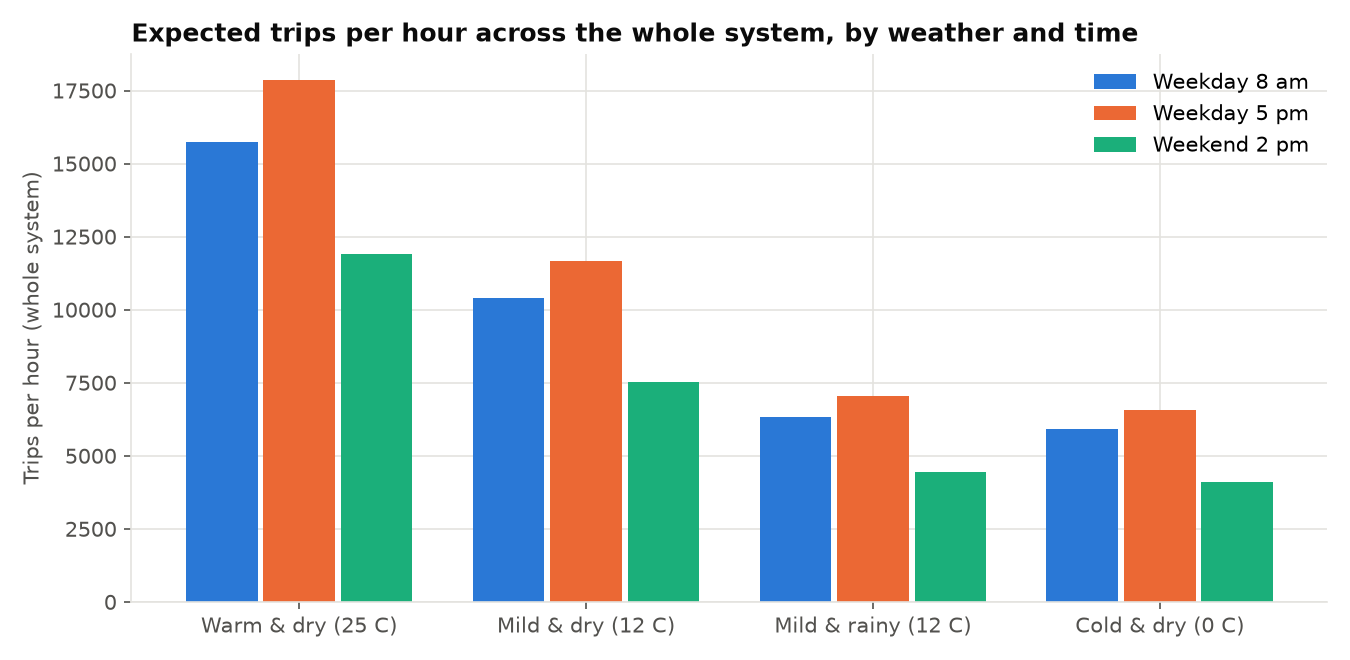

In [29]:
from IPython.display import Image, display

display(Image("outputs/figures/12_demand_scenarios.png", width=900))

## Part 6 - Summary of results and verdicts

| Hypothesis | Result | Verdict |
|---|---|---|
| H1 Warmer hours have more trips | +2.5% trips per +1 C | Supported |
| H2 Rain lowers trips at similar temperatures | -33% in a rainy hour | Supported |
| H3 Casual riders more weather-sensitive | Temperature +4.4% vs +2.1%; rain intervals overlap | Inconclusive |
| H4 Casual trips are longer | Median 12.4 vs 8.2 minutes | Supported |
| H5 Weekends: weaker commute peaks, more casual riders | Peak ratio 2.0 vs 0.84; casual share 15% vs 23% | Supported |

Results show association, not causation; the report's roadmap proposes a pilot (A/B) test before full roll-out.